# Mini-Project 5: Taxi Route Revenue, Pricing & Fleet Planner

**The scenario.** A matatu association runs 14-seater vehicles on three
routes out of Kampala. It wants to forecast demand, understand whether its
fares are right, and decide how many vehicles to deploy.

**The data.** Daily passenger counts over ten days. The Ntinda figures come
from the brief; Entebbe and Mukono are *illustrative*.

**Where the code lives.** `src/projects/p5_taxi.py`. Note that
`RouteLinearTrend` **inherits** mini-project 1's `LinearTrendModel` rather
than reimplementing it: fitting a straight line with `np.polyfit` is the same
operation whether the series is a district population or a passenger count.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import statistics

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.core.forecaster import Forecaster
from src.core.plotting import PALETTE, apply_style, save
from src.projects.p1_population import LinearTrendModel
from src.projects.p5_taxi import (
    FAMILY, DriftModel, ExponentialSmoothingModel, FleetPlanner, MarketModel,
    MovingAverageModel, Route, RouteLinearTrend, SeasonalNaiveModel, WalkForward,
    load_routes, simulate_weekly_demand)

apply_style()
SEED = 7
rng = np.random.default_rng(SEED)
pd.set_option("display.float_format", "{:,.3f}".format)

routes = load_routes()
for route in routes:
    print(repr(route))

Route('Kampala-Ntinda', days=10, fare=UGX 2,000, total=UGX 948,000)
Route('Kampala-Entebbe', days=10, fare=UGX 5,000, total=UGX 3,390,000)
Route('Kampala-Mukono', days=10, fare=UGX 3,000, total=UGX 1,560,000)


## Task 1: the `Route` class

In [2]:
pd.DataFrame([{"route": r.name, "fare_ugx": r.fare, "days": len(r),
               **r.stats(), "total_revenue_ugx": r.total_revenue}
              for r in routes]).set_index("route")

,fare_ugx,days,mean,median,variance,stdev,cv,total_revenue_ugx
route,,,,,,,,
Kampala-Ntinda,"2,000.000",10,47.400,47.500,54.267,7.367,0.155,"948,000.000"
Kampala-Entebbe,"5,000.000",10,67.800,67.000,45.067,6.713,0.099,"3,390,000.000"
Kampala-Mukono,"3,000.000",10,52.000,50.500,26.444,5.142,0.099,"1,560,000.000"


In [3]:
# Hand-check Ntinda end to end.
ntinda = routes[0]
assert ntinda.passengers.sum() == 474
assert np.isclose(ntinda.total_revenue, 474 * 2_000)
print(f"Ntinda: {ntinda.passengers.sum():.0f} passengers x UGX "
      f"{ntinda.fare:,.0f} = UGX {ntinda.total_revenue:,.0f}  [checked]")
print(f"\nEntebbe earns {routes[1].total_revenue / ntinda.total_revenue:.1f}x "
      f"Ntinda's revenue on only "
      f"{routes[1].passengers.sum() / ntinda.passengers.sum():.1f}x the passengers,")
print("because its fare is 2.5x higher. Passenger counts alone would rank the")
print("routes wrongly for any revenue decision.")

Ntinda: 474 passengers x UGX 2,000 = UGX 948,000  [checked]

Entebbe earns 3.6x Ntinda's revenue on only 1.4x the passengers,
because its fare is 2.5x higher. Passenger counts alone would rank the
routes wrongly for any revenue decision.


In [4]:
daily = pd.DataFrame({r.name: r.daily_revenue for r in routes},
                     index=range(1, 11))
daily.index.name = "day"
daily

,Kampala-Ntinda,Kampala-Entebbe,Kampala-Mukono
day,,,
1,"70,000.000","300,000.000","135,000.000"
2,"80,000.000","290,000.000","141,000.000"
3,"84,000.000","325,000.000","150,000.000"
4,"100,000.000","350,000.000","147,000.000"
5,"110,000.000","360,000.000","165,000.000"
6,"120,000.000","400,000.000","186,000.000"
7,"96,000.000","375,000.000","174,000.000"
8,"104,000.000","340,000.000","159,000.000"
9,"94,000.000","330,000.000","153,000.000"


## Task 2: is the Ntinda fare right?

With demand $Q_d = 120 - 0.02P$ and supply $Q_s = 10 + 0.03P$, writing both
as $Q + 0.02P = 120$ and $Q - 0.03P = 10$ gives a 2x2 system in $(P, Q)$
that `scipy.linalg.solve` handles directly.

In [5]:
market = MarketModel()
A, b = market.system()
print("coefficient matrix (columns are P, Q):")
print(A)
print("right-hand side:", b)
print(f"\ndeterminant = {market.determinant:.4f}, "
      f"condition number = {market.condition_number:.2f}")

price, quantity = market.equilibrium()
print(f"\nequilibrium fare     P* = UGX {price:,.0f}")
print(f"equilibrium quantity Q* = {quantity:,.0f} passengers per trip-hour")

# Verify against the algebra: 120 - 0.02P = 10 + 0.03P  ->  P = 110/0.05
assert np.isclose(price, 110 / 0.05) and np.isclose(quantity, 120 - 0.02 * price)
print("\n[checked] matches solving 110 = 0.05P by hand")

coefficient matrix (columns are P, Q):
[[ 0.02  1.  ]
 [-0.03  1.  ]]
right-hand side: [120.  10.]

determinant = 0.0500, condition number = 40.00

equilibrium fare     P* = UGX 2,200
equilibrium quantity Q* = 76 passengers per trip-hour

[checked] matches solving 110 = 0.05P by hand


In [6]:
gap = market.gap_at(2_000)
pd.Series(gap).to_frame("value")

,value
price,"2,000.000"
demanded,80.000
supplied,70.000
excess_demand,10.000
distance_from_equilibrium,-200.000


**Interpretation.** The current fare of UGX 2,000 is **UGX 200 below** the
market-clearing level of UGX 2,200. At that price 80 passengers per trip-hour
want a ride but only 70 trip-hours of capacity are offered, so there is a
persistent **shortage of about 10 passengers per trip-hour** -- queues at the
stage, full vehicles passing waiting passengers, and the informal premiums
that appear whenever a posted price sits below the clearing one.

Raising the fare to UGX 2,200 would close the gap from both sides at once:
it would price out the four least-willing passengers and draw in six more
trip-hours of supply. Whether the association *should* do that is a different
question -- the model says nothing about who those four passengers are, and a
10% fare rise on a commuter route is regressive -- but the shortage is not
something better scheduling can fix. It is a price signal.

saved: mp5_equilibrium.png


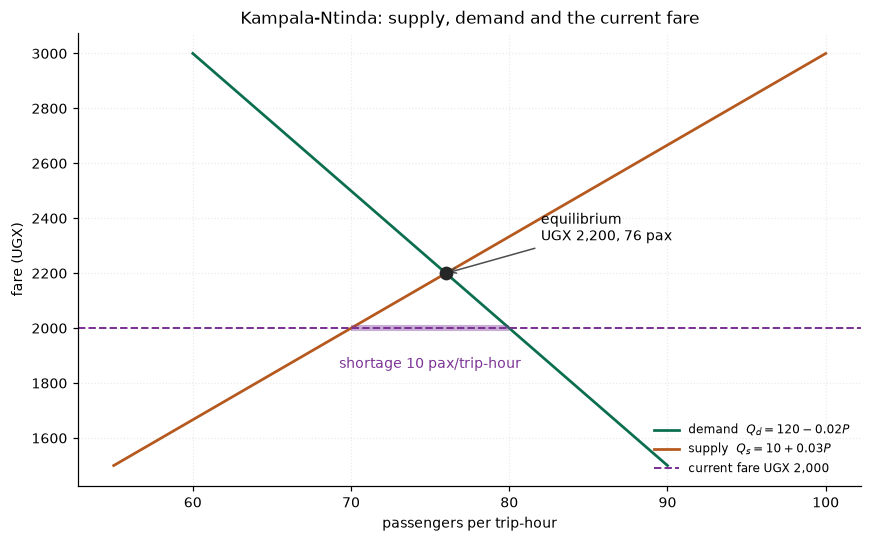

In [7]:
fares = np.linspace(1_500, 3_000, 200)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot([market.quantity_demanded(p) for p in fares], fares, color=PALETTE[0],
        lw=1.8, label="demand  $Q_d = 120 - 0.02P$")
ax.plot([market.quantity_supplied(p) for p in fares], fares, color=PALETTE[1],
        lw=1.8, label="supply  $Q_s = 10 + 0.03P$")
ax.plot([quantity], [price], "o", color="0.15", ms=8, zorder=5)
ax.annotate(f"equilibrium\nUGX {price:,.0f}, {quantity:.0f} pax",
            xy=(quantity, price), xytext=(quantity + 6, price + 120), fontsize=9,
            arrowprops=dict(arrowstyle="->", color="0.3"))
ax.axhline(2_000, color=PALETTE[3], ls="--", lw=1.3, label="current fare UGX 2,000")
ax.plot([gap["supplied"], gap["demanded"]], [2_000, 2_000], color=PALETTE[3],
        lw=4, alpha=0.4, solid_capstyle="butt")
ax.annotate(f"shortage {gap['excess_demand']:.0f} pax/trip-hour",
            xy=((gap["supplied"] + gap["demanded"]) / 2, 2_000),
            xytext=(0, -26), textcoords="offset points", ha="center", fontsize=9,
            color=PALETTE[3])
ax.set_xlabel("passengers per trip-hour")
ax.set_ylabel("fare (UGX)")
ax.set_title("Kampala-Ntinda: supply, demand and the current fare")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
print("saved:", save(fig, "mp5_equilibrium.png").name)
plt.show()

## Task 3: the forecasting models

All subclass the shared abstract `Forecaster`. Four are compared here: the
association's existing 3-day moving average, simple exponential smoothing
with a tunable alpha, a linear trend, and a drift model.

In [8]:
print("models registered in the taxi family:")
for label, klass in sorted(Forecaster.catalogue(FAMILY).items()):
    print(f"  {label:<16} {klass.__name__}")

print("\nRouteLinearTrend reuses mini-project 1's implementation:")
print("  issubclass(RouteLinearTrend, LinearTrendModel) =",
      issubclass(RouteLinearTrend, LinearTrendModel))
print("  same fit method                                =",
      RouteLinearTrend.fit is LinearTrendModel.fit)
print("  only the registered family differs             =",
      f"{LinearTrendModel.family!r} -> {RouteLinearTrend.family!r}")

models registered in the taxi family:
  drift            DriftModel
  linear-trend     RouteLinearTrend
  moving-average   MovingAverageModel
  seasonal-naive   SeasonalNaiveModel
  ses              ExponentialSmoothingModel

RouteLinearTrend reuses mini-project 1's implementation:
  issubclass(RouteLinearTrend, LinearTrendModel) = True
  same fit method                                = True
  only the registered family differs             = 'population' -> 'taxi'


In [9]:
builders = {
    "moving-average(3)": lambda: MovingAverageModel(3),
    "ses(0.5)": lambda: ExponentialSmoothingModel(0.5),
    "linear-trend": RouteLinearTrend,
    "drift": DriftModel,
}
demo = {name: build().fit(ntinda.passengers).predict(1)[0]
        for name, build in builders.items()}
print("day-11 passenger forecast for Ntinda, each model fitted on all ten days:")
pd.Series(demo, name="passengers").to_frame().round(2)

day-11 passenger forecast for Ntinda, each model fitted on all ten days:


,passengers
moving-average(3),48.000
ses(0.5),47.190
linear-trend,53.670
drift,46.110


## Task 4: rolling-origin backtesting over days 4-10

At each origin the model is refitted on everything observed so far and asked
for one step. This matters: scoring on a fixed hold-out would let a model
trained on all ten days be judged on days it had already seen. Walk-forward
reproduces the forecast the association could actually have made on the
morning of each day.

In [10]:
backtests = {r.name: WalkForward(r.passengers, first_day=4) for r in routes}
print(backtests[ntinda.name], f"-> {len(backtests[ntinda.name])} one-step forecasts")

backtests[ntinda.name].forecasts(lambda: MovingAverageModel(3)).round(2)

WalkForward(n=10, days 4-10) -> 7 one-step forecasts


,actual,forecast
day,,
4,50.000,39.000
5,55.000,44.000
6,60.000,49.000
7,48.000,55.000
8,52.000,54.330
9,47.000,53.330
10,45.000,49.000


In [11]:
for name, backtest in backtests.items():
    print(f"\n=== {name} " + "=" * (46 - len(name)))
    print(backtest.compare(builders).to_string())


=== Kampala-Ntinda ================================
                    MAE  RMSE  MAPE_%
model                                
drift             4.895 7.368  10.218
ses(0.5)          6.719 7.552  12.999
moving-average(3) 7.524 8.225  14.538
linear-trend      7.873 9.682  16.380

=== Kampala-Entebbe ===============================
                    MAE  RMSE  MAPE_%
model                                
drift             4.747 5.628   6.672
ses(0.5)          6.045 6.737   8.510
moving-average(3) 7.190 7.765  10.192
linear-trend      7.711 9.054  11.264

=== Kampala-Mukono ================================
                    MAE  RMSE  MAPE_%
model                                
ses(0.5)          4.377 5.301   7.885
drift             4.589 4.976   8.404
moving-average(3) 5.333 6.008   9.693
linear-trend      6.391 6.907  11.991


In [12]:
mae_table = pd.DataFrame({
    name: {label: backtest.score(build).mae for label, build in builders.items()}
    for name, backtest in backtests.items()})
mae_table.index.name = "model"
print("walk-forward MAE (passengers), by model and route:")
mae_table

walk-forward MAE (passengers), by model and route:


,Kampala-Ntinda,Kampala-Entebbe,Kampala-Mukono
model,,,
moving-average(3),7.524,7.190,5.333
ses(0.5),6.719,6.045,4.377
linear-trend,7.873,7.711,6.391
drift,4.895,4.747,4.589


### Tuning the smoothing constant

In [13]:
tuned = {}
for name, backtest in backtests.items():
    best, scores = backtest.tune_alpha()
    tuned[name] = {"best alpha": best, "MAE at best": scores.min(),
                   "MAE at 0.5": scores[0.5]}
tuning = pd.DataFrame(tuned).T
tuning

,best alpha,MAE at best,MAE at 0.5
Kampala-Ntinda,1.000,5.857,6.719
Kampala-Entebbe,1.000,4.429,6.045
Kampala-Mukono,1.000,3.714,4.377


saved: mp5_alpha_tuning.png


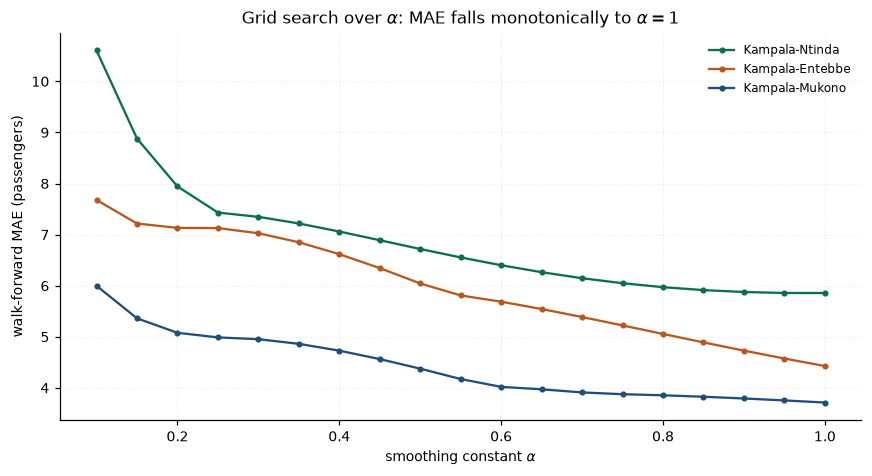

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.4))
for index, (name, backtest) in enumerate(backtests.items()):
    _, scores = backtest.tune_alpha()
    ax.plot(scores.index, scores.to_numpy(), "o-", color=PALETTE[index], ms=3,
            label=name)
ax.set_xlabel(r"smoothing constant $\alpha$")
ax.set_ylabel("walk-forward MAE (passengers)")
ax.set_title(r"Grid search over $\alpha$: MAE falls monotonically to $\alpha = 1$")
ax.legend(fontsize=8)
fig.tight_layout()
print("saved:", save(fig, "mp5_alpha_tuning.png").name)
plt.show()

**The tuning result is itself the finding.** On all three routes the MAE
falls monotonically as alpha rises, and the grid search lands on
**alpha = 1.0** -- which is simple exponential smoothing collapsing into the
naive forecast "tomorrow equals today". That is not a failure of the search;
it is the data saying there is no exploitable signal in the older
observations. With ten points and no visible trend or seasonality, the most
recent count genuinely is the best available predictor, and any smoothing
just drags the forecast toward a stale average. The sensible reading is that
the association should not buy a forecasting system on this evidence -- it
should collect more data first.

## Task 5: day-11 revenue

In [15]:
day11 = []
for route in routes:
    backtest = backtests[route.name]
    best_alpha, _ = backtest.tune_alpha()
    winner = backtest.compare(builders).index[0]
    model = builders[winner]().fit(route.passengers)
    passengers = float(model.predict(1)[0])
    day11.append({"route": route.name, "best model": winner,
                  "tuned alpha": best_alpha,
                  "day-11 passengers": passengers,
                  "fare_ugx": route.fare,
                  "day-11 revenue_ugx": passengers * route.fare})
forecast_table = pd.DataFrame(day11).set_index("route")
forecast_table

,best model,tuned alpha,day-11 passengers,fare_ugx,day-11 revenue_ugx
route,,,,,
Kampala-Ntinda,drift,1.000,46.111,"2,000.000","92,222.222"
Kampala-Entebbe,drift,1.000,64.444,"5,000.000","322,222.222"
Kampala-Mukono,ses(0.5),1.000,51.555,"3,000.000","154,664.062"


saved: mp5_revenue_forecast.png


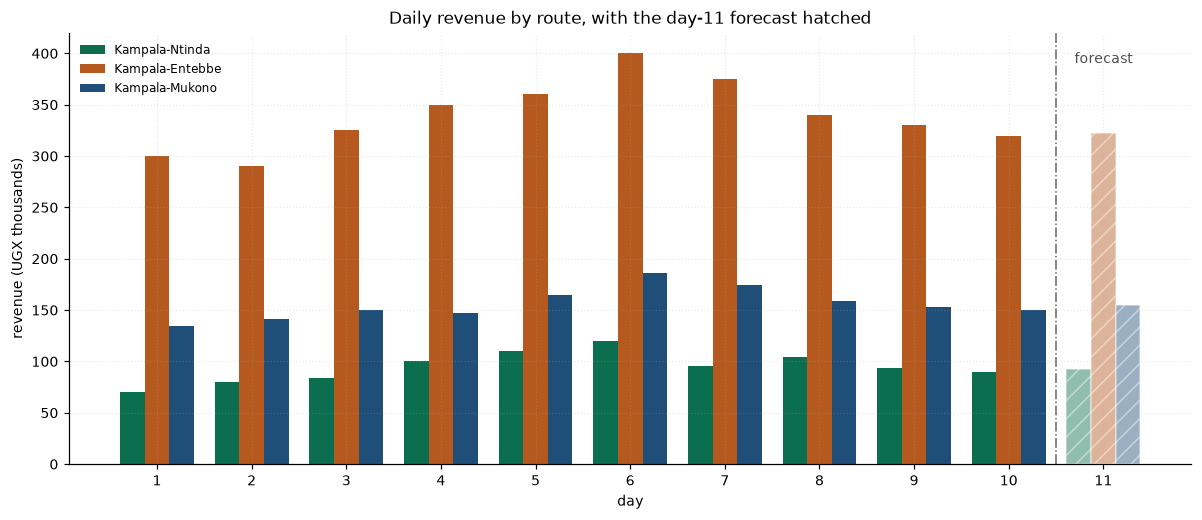

In [16]:
fig, ax = plt.subplots(figsize=(11, 4.8))
width = 0.26
positions = np.arange(1, 12)
for index, route in enumerate(routes):
    offset = (index - 1) * width
    ax.bar(positions[:10] + offset, route.daily_revenue / 1_000, width=width,
           color=PALETTE[index], label=route.name)
    predicted = forecast_table.loc[route.name, "day-11 revenue_ugx"] / 1_000
    ax.bar([11 + offset], [predicted], width=width, color=PALETTE[index],
           alpha=0.45, hatch="//", edgecolor="white")

ax.axvline(10.5, color="0.4", lw=1, ls="-.")
ax.annotate("forecast", xy=(11, ax.get_ylim()[1] * 0.93), ha="center", fontsize=9,
            color="0.3")
ax.set_xticks(positions, [str(d) for d in positions])
ax.set_xlabel("day")
ax.set_ylabel("revenue (UGX thousands)")
ax.set_title("Daily revenue by route, with the day-11 forecast hatched")
ax.legend(fontsize=8)
fig.tight_layout()
print("saved:", save(fig, "mp5_revenue_forecast.png").name)
plt.show()

## Task 6: how many vehicles on day 11?

Each vehicle makes 8 one-way trips a day at 14 seats, so it can carry 112
passengers. A 15% buffer is added, and the result is rounded **up** with a
floor of one vehicle: a stranded passenger costs the association a fare and
a reputation, while an under-filled seat costs only fuel.

In [17]:
planner = FleetPlanner(seats=14, trips_per_day=8, buffer=0.15)
print(f"capacity per vehicle: {planner.seats} seats x {planner.trips_per_day} "
      f"trips = {planner.capacity} passengers/day")

plan = planner.plan(dict(zip(forecast_table.index,
                             forecast_table["day-11 passengers"])))
plan

capacity per vehicle: 14 seats x 8 trips = 112 passengers/day


,forecast passengers,with buffer,vehicles
route,,,
Kampala-Ntinda,46.111,53.028,1
Kampala-Entebbe,64.444,74.111,1
Kampala-Mukono,51.555,59.288,1


**The answer depends on what the counts measure, and the brief does not
say.** Read as *daily totals*, every route needs one vehicle: 45-64
passengers against a 112-passenger daily capacity, so a single matatu covers
any of them with room to spare. That is almost certainly not what the
association means -- three routes out of Kampala plainly run more than three
vehicles between them.

Read instead as *passengers per trip-hour at the stage*, which is the same
unit the equilibrium analysis in task 2 uses, the picture changes completely.
Below is the same calculation under that reading, assuming a 12-hour
operating day.

In [18]:
hourly = {}
for route in routes:
    per_hour = forecast_table.loc[route.name, "day-11 passengers"]
    hourly[route.name] = per_hour * 12          # a 12-hour operating day
hourly_plan = planner.plan(hourly)
hourly_plan

,forecast passengers,with buffer,vehicles
route,,,
Kampala-Ntinda,553.333,636.333,6
Kampala-Entebbe,773.333,889.333,8
Kampala-Mukono,618.656,711.455,7


In [19]:
print("vehicles required under each reading of the data:")
print(pd.DataFrame({"daily totals": plan["vehicles"],
                    "hourly stage counts": hourly_plan["vehicles"]}).to_string())
print("\nThe two readings differ by a factor of twelve, and nothing in the data")
print("distinguishes them. This is worth flagging to the association rather")
print("than resolving silently: the fleet decision turns entirely on a")
print("definition that the brief leaves open.")

vehicles required under each reading of the data:
                 daily totals  hourly stage counts
route                                             
Kampala-Ntinda              1                    6
Kampala-Entebbe             1                    8
Kampala-Mukono              1                    7

The two readings differ by a factor of twelve, and nothing in the data
distinguishes them. This is worth flagging to the association rather
than resolving silently: the fleet decision turns entirely on a
definition that the brief leaves open.


## Extension: 60 days with a weekly pattern

Ten days is too short for any seasonal model to find anything. Simulating 60
days with a realistic weekly rhythm -- busier on Fridays, much quieter on
Sundays -- gives the seasonal-naive model something to work with, and shows
what the moving average was missing all along.

In [20]:
simulated = simulate_weekly_demand(days=60, base=50, seed=SEED)
weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_weekday = pd.Series({weekday_names[i]: simulated[i::7].mean() for i in range(7)},
                       name="mean passengers")
by_weekday.to_frame().round(1)

,mean passengers
Mon,50.400
Tue,51.100
Wed,52.000
Thu,53.300
Fri,63.000
Sat,45.200
Sun,35.400


In [21]:
extended = {
    "moving-average(3)": lambda: MovingAverageModel(3),
    "ses(0.5)": lambda: ExponentialSmoothingModel(0.5),
    "drift": DriftModel,
    "seasonal-naive(7)": lambda: SeasonalNaiveModel(7),
}
long_backtest = WalkForward(simulated, first_day=15)
print(f"{len(long_backtest)} one-step forecasts over days 15-60\n")
long_backtest.compare(extended)

46 one-step forecasts over days 15-60



,MAE,RMSE,MAPE_%
model,,,
seasonal-naive(7),4.000,4.926,8.054
ses(0.5),8.215,9.618,17.656
moving-average(3),8.370,10.110,18.178
drift,9.252,11.082,19.370


In [22]:
seasonal_mae = long_backtest.score(lambda: SeasonalNaiveModel(7)).mae
moving_mae = long_backtest.score(lambda: MovingAverageModel(3)).mae
print(f"seasonal-naive MAE : {seasonal_mae:.3f} passengers")
print(f"moving-average MAE : {moving_mae:.3f} passengers")
print(f"improvement        : {1 - seasonal_mae / moving_mae:.0%}")

seasonal-naive MAE : 4.000 passengers
moving-average MAE : 8.370 passengers
improvement        : 52%


saved: mp5_seasonal_extension.png


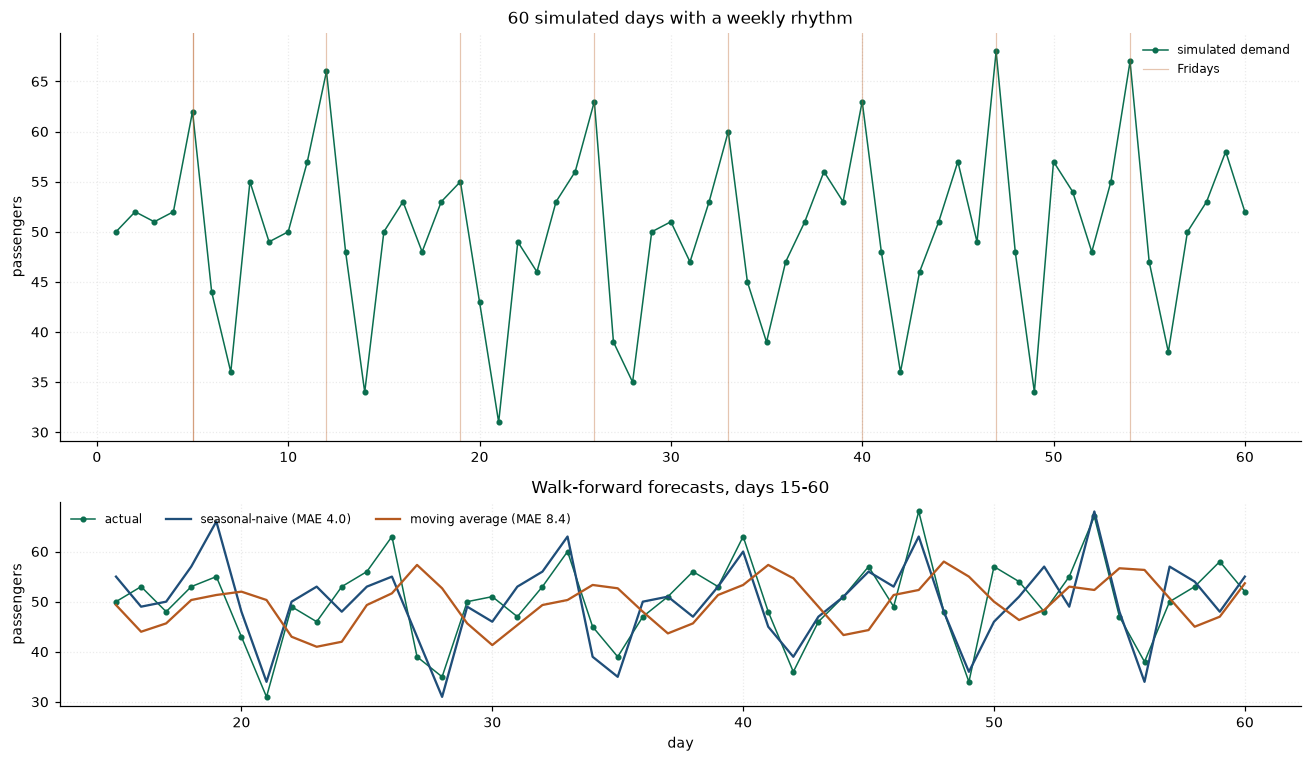

In [23]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), height_ratios=[2, 1])

axes[0].plot(np.arange(1, 61), simulated, "o-", color=PALETTE[0], ms=3, lw=1,
             label="simulated demand")
for friday in range(4, 60, 7):
    axes[0].axvline(friday + 1, color=PALETTE[1], lw=0.8, alpha=0.35)
axes[0].axvline(5, color=PALETTE[1], lw=0.8, alpha=0.35, label="Fridays")
axes[0].set_ylabel("passengers")
axes[0].set_title("60 simulated days with a weekly rhythm")
axes[0].legend(fontsize=8)

comparison = long_backtest.forecasts(lambda: SeasonalNaiveModel(7)).join(
    long_backtest.forecasts(lambda: MovingAverageModel(3))["forecast"],
    rsuffix="_ma")
axes[1].plot(comparison.index, comparison["actual"], "o-", color=PALETTE[0], ms=3,
             lw=1, label="actual")
axes[1].plot(comparison.index, comparison["forecast"], "-", color=PALETTE[2],
             lw=1.5, label=f"seasonal-naive (MAE {seasonal_mae:.1f})")
axes[1].plot(comparison.index, comparison["forecast_ma"], "-", color=PALETTE[1],
             lw=1.5, label=f"moving average (MAE {moving_mae:.1f})")
axes[1].set_xlabel("day")
axes[1].set_ylabel("passengers")
axes[1].set_title("Walk-forward forecasts, days 15-60")
axes[1].legend(fontsize=8, ncol=3)

fig.tight_layout()
print("saved:", save(fig, "mp5_seasonal_extension.png").name)
plt.show()

The lower panel shows exactly why. The moving average smooths across the
week, so it is always wrong in the same way: too low on Friday, too high on
Sunday, every single week. Its errors are not noise, they are a systematic
pattern it is structurally incapable of representing. The seasonal-naive
model carries the weekly shape by construction and its remaining error is
just the week-to-week noise.

## Findings & Limitations

**Findings.** The Ntinda market clears at **P\* = UGX 2,200** with
**Q\* = 76** passengers per trip-hour, so the current UGX 2,000 fare sits
UGX 200 below equilibrium and sustains a shortage of about 10 passengers per
trip-hour -- queues and informal premiums rather than anything scheduling can
fix. Revenue ranking is driven by fare, not volume: Entebbe earns 3.6x
Ntinda's revenue on 1.4x the passengers. In walk-forward backtesting over
days 4-10, the drift model wins on Ntinda and Entebbe and SES wins on Mukono,
but the more telling result is the alpha grid search, which lands on
**alpha = 1.0** on all three routes: exponential smoothing collapses into the
naive forecast, meaning ten observations contain no exploitable structure
beyond the most recent count. On fleet sizing, the honest answer is that it
depends on a definition the brief leaves open: read as daily totals every
route needs **one vehicle**, read as hourly stage counts over a 12-hour day
each needs **6-8**. The factor of twelve between those answers is not a
modelling choice and should be put back to the association. The extension
settles the forecasting question: given 60 days with a genuine weekly
pattern, a seasonal-naive model cuts MAE from 8.4 to 4.0 passengers, a 52%
improvement, because the moving average's errors are not noise but the weekly
shape it cannot represent.

**Limitations.** Ten days is too short to fit anything, which is why every
model converges on the naive forecast and why the extension had to simulate
data to make the seasonal comparison at all; with real data the ranking could
easily reverse. The Entebbe and Mukono series are illustrative, so only the
Ntinda results rest on the brief's own figures. The supply and demand curves
are assumed linear with coefficients given rather than estimated, and real
demand is almost certainly non-linear and depends on fuel price, weather and
the fares on competing routes, none of which is modelled -- the equilibrium
should be read as the direction of the mispricing, not a precise target. The
fleet calculation assumes every vehicle runs full on every trip, which no
matatu does; a realistic load factor of 70-80% would raise the counts by
roughly a third. Finally, the analysis treats the three routes as
independent, when in practice they compete for the same vehicles and the same
drivers, so a genuine fleet plan is one allocation problem rather than three
separate ones.